In [2]:
import pandas as pd
import numpy as np
# Сгенерируйте данные о клиентах, включающие:


data = {
    'CustomerID': list(range(1, 61)),
    'Age': [25, np.nan, 35, 45, np.nan, 55, 65, 25, 35, 45] * 6,
    'AveragePurchaseValue': [100, 200, 300, np.nan, 400, 500, 600, np.nan, 700, 800] * 6,
    'PurchaseFrequency': [1, 2, 3, 4, 5, np.nan] * 10
}
# Display the DataFrame
df = pd.DataFrame(data)
df

,CustomerID,Age,AveragePurchaseValue,PurchaseFrequency
0,1,25.0,100.0,1.0
1,2,NaN,200.0,2.0
2,3,35.0,300.0,3.0
3,4,45.0,NaN,4.0
4,5,NaN,400.0,5.0
5,6,55.0,500.0,NaN
6,7,65.0,600.0,1.0
7,8,25.0,NaN,2.0
8,9,35.0,700.0,3.0
9,10,45.0,800.0,4.0


In [3]:
df.describe()
# Проведите предварительный анализ данных и оцените их структуру, основные характеристики и распределения признаков.

,CustomerID,Age,AveragePurchaseValue,PurchaseFrequency
count,60.000000,48.000000,48.000000,50.000000
mean,30.500000,41.250000,450.000000,3.000000
std,17.464249,13.308932,231.553495,1.428571
min,1.000000,25.000000,100.000000,1.000000
25%,15.750000,32.500000,275.000000,2.000000
50%,30.500000,40.000000,450.000000,3.000000
75%,45.250000,47.500000,625.000000,4.000000
max,60.000000,65.000000,800.000000,5.000000


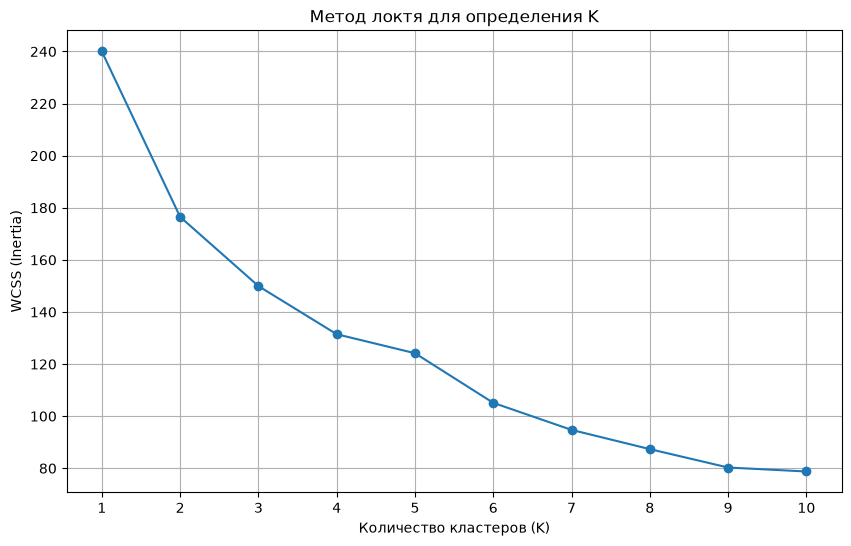

In [13]:
# Подготовьте данные к кластеризации, выполнив необходимые преобразования и нормализацию признаков.


df['AveragePurchaseValue'] =  df['AveragePurchaseValue'].fillna(df['AveragePurchaseValue'].median())
df['PurchaseFrequency'] = df['PurchaseFrequency'].fillna(df['PurchaseFrequency'].median())
df['Age'] = df['Age'].fillna(df['Age'].mean())


from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# Нормализация данных
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

# Определение оптимального количества кластеров (Метод локтя - Elbow Method)
# Данный блок кода используется для поиска наиболее подходящего количества кластеров (K)
# для алгоритма KMeans. KMeans работает лучше, когда кластеры имеют сопоставимый размер и
# распределение признаков. "Метод локтя" (Elbow Method) помогает найти это K,
# основываясь на мере внутренней согласованности - WCSS (Within-Cluster Sum of Squares)
# или Инерсии.
#
# WCSS показывает сумму квадратов расстояний между точками внутри одного кластера и его
# центром (центроидом). Чем меньше WCSS, тем более плотно и когерентно кластеры.
#
# Мы перебираем количество кластеров K от 1 до 10. Для каждого K мы запускаем KMeans
# и фиксируем значение WCSS (inertia_).
#
# Затем мы строим график. Точка на графике, где кривая резко замедляется (похожа на
# "локоть" или "сгиб"), указывает на оптимальное K. Это означает, что дальнейшее
# увеличение K приносит лишь незначительное улучшение в плотности кластера.
wcss = [] # Within-Cluster Sum of Squares
inertia = []
K_range = range(1, 11) # Диапазон для проверки от 1 до 10 кластеров

for k in K_range:
    # Инициализация и обучение модели KMeans для текущего количества кластеров k
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)
    wcss.append(kmeans.inertia_) # WCSS и Inertia одинаковы

# Визуализация метода локтя
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, marker='o')
plt.title('Метод локтя для определения K')
plt.xlabel('Количество кластеров (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range)
plt.grid(True)
# Убираем figtext для предотвращения наложения текста с графиком
# Если нужно добавить пояснение, лучше использовать текстовые аннотации поверх графика или в отдельной ячейке
# или изменить подписи осей.
plt.show()
plt.show()

# Примечание: Анализируйте график, чтобы найти "локоть" – точку, где уменьшение WCSS начинает замедляться.
